In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
stores = pd.read_csv("stores.csv")
products = pd.read_csv("products.csv")
customers = pd.read_csv("customers.csv")
orders = pd.read_csv("orders.csv")
order_items = pd.read_csv("order_items.csv")
inventory = pd.read_csv("inventory_daily.csv")
feedback = pd.read_csv("customer_feedback.csv")
complaints = pd.read_csv("complaints.csv")

In [3]:
datasets = {
    "Stores": stores,
    "Products": products,
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Inventory": inventory,
    "Feedback": feedback,
    "Complaints": complaints
}

for name, df in datasets.items():
    print(name, ":", df.shape)

Stores : (30, 8)
Products : (50, 7)
Customers : (20000, 6)
Orders : (40000, 13)
Order Items : (100000, 9)
Inventory : (12000, 11)
Feedback : (8001, 9)
Complaints : (2000, 9)


In [4]:
orders.head()

,order_id,order_date,order_time,store_id,customer_id,sales_channel,order_status,payment_method,subtotal,discount_amount,net_sales,tax_amount,order_total
0,O0000001,2025-01-27,15:00:00,S020,C003545,Zomato,Cancelled,UPI,876.0,11.90,864.10,43.21,907.31
1,O0000002,2025-06-06,21:15:00,S024,C014542,Swiggy,Completed,UPI,328.0,62.65,265.35,13.27,278.62
2,O0000003,2025-12-09,21:30:00,S009,C011297,Takeaway,Completed,Cash,387.0,19.35,367.65,18.38,386.03
3,O0000004,2025-05-16,16:30:00,S009,C003679,Dine-in,Completed,Card,935.0,0.00,935.00,46.75,981.75
4,O0000005,2025-12-29,20:00:00,S010,C005335,Zomato,Completed,UPI,268.0,22.35,245.65,12.28,257.93


In [5]:
orders.tail()

,order_id,order_date,order_time,store_id,customer_id,sales_channel,order_status,payment_method,subtotal,discount_amount,net_sales,tax_amount,order_total
39995,O0039996,2025-03-15,20:30:00,S007,C012818,Zomato,Completed,Wallet,915.0,12.90,902.10,45.10,947.20
39996,O0039997,2025-07-27,12:30:00,S010,C013136,Zomato,Completed,Cash,397.0,19.35,377.65,18.88,396.53
39997,O0039998,2025-02-07,16:30:00,S003,C009252,Zomato,Completed,Cash,1212.0,28.35,1183.65,59.18,1242.83
39998,O0039999,2025-07-09,18:45:00,S015,C010449,Zomato,Completed,Cash,707.0,55.80,651.20,32.56,683.76
39999,O0040000,2025-02-19,19:30:00,S013,C000274,Dine-in,Completed,UPI,2082.0,208.05,1873.95,93.70,1967.65


In [6]:
orders.sample(5)

,order_id,order_date,order_time,store_id,customer_id,sales_channel,order_status,payment_method,subtotal,discount_amount,net_sales,tax_amount,order_total
10071,O0010072,2025-03-06,19:30:00,S029,C015999,Zomato,Completed,Wallet,1116.0,195.30,920.70,46.04,966.74
21653,O0021654,2025-12-20,13:00:00,S002,C002182,Zomato,Completed,Cash,1185.0,0.00,1185.00,59.25,1244.25
2740,O0002741,2025-02-17,12:15:00,S028,C019887,Dine-in,Completed,UPI,696.0,0.00,696.00,34.80,730.80
37427,O0037428,2025-07-18,11:45:00,S025,C014992,Dine-in,Completed,Cash,1406.0,27.90,1378.10,68.90,1447.00
32436,O0032437,2025-06-01,10:45:00,S005,C003928,Takeaway,Completed,UPI,586.0,41.75,544.25,27.21,571.46


In [7]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         40000 non-null  object 
 1   order_date       40000 non-null  object 
 2   order_time       40000 non-null  object 
 3   store_id         40000 non-null  object 
 4   customer_id      40000 non-null  object 
 5   sales_channel    40000 non-null  object 
 6   order_status     40000 non-null  object 
 7   payment_method   40000 non-null  object 
 8   subtotal         40000 non-null  float64
 9   discount_amount  40000 non-null  float64
 10  net_sales        40000 non-null  float64
 11  tax_amount       40000 non-null  float64
 12  order_total      40000 non-null  float64
dtypes: float64(5), object(8)
memory usage: 4.0+ MB


In [8]:
orders.describe()

,subtotal,discount_amount,net_sales,tax_amount,order_total
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,764.255950,36.532710,727.723240,36.386524,764.109763
std,350.806046,48.151694,337.169051,16.858392,354.027443
min,198.000000,0.000000,171.000000,8.550000,179.550000
25%,507.000000,0.000000,480.137500,24.010000,504.147500
50%,697.000000,19.950000,662.200000,33.110000,695.310000
75%,947.000000,54.750000,900.662500,45.032500,945.695000
max,3191.000000,677.700000,3011.450000,150.570000,3162.020000


In [9]:
orders["order_status"].value_counts()

order_status
Completed    36798
Cancelled     1990
Refunded      1212
Name: count, dtype: int64

In [10]:
orders["sales_channel"].str.strip().str.lower().value_counts()

sales_channel
dine-in     13762
swiggy      12472
zomato      10538
takeaway     3228
Name: count, dtype: int64

In [11]:
orders["sales_channel_clean"] = (
    orders["sales_channel"].str.strip().str.lower()
)

In [12]:
orders[["sales_channel","sales_channel_clean"]].head(10)

,sales_channel,sales_channel_clean
0,Zomato,zomato
1,Swiggy,swiggy
2,Takeaway,takeaway
3,Dine-in,dine-in
4,Zomato,zomato
5,Dine-in,dine-in
6,Takeaway,takeaway
7,Zomato,zomato
8,Dine-in,dine-in
9,Swiggy,swiggy


In [13]:
orders.duplicated().sum()

np.int64(0)

In [14]:
orders.isnull().sum()

order_id               0
order_date             0
order_time             0
store_id               0
customer_id            0
sales_channel          0
order_status           0
payment_method         0
subtotal               0
discount_amount        0
net_sales              0
tax_amount             0
order_total            0
sales_channel_clean    0
dtype: int64

In [15]:
orders["order_date"]=pd.to_datetime(orders["order_date"])

In [16]:
orders["order_time"] = pd.to_datetime(
    orders["order_time"],
    format="%H:%M:%S"
    )

In [17]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             40000 non-null  object        
 1   order_date           40000 non-null  datetime64[ns]
 2   order_time           40000 non-null  datetime64[ns]
 3   store_id             40000 non-null  object        
 4   customer_id          40000 non-null  object        
 5   sales_channel        40000 non-null  object        
 6   order_status         40000 non-null  object        
 7   payment_method       40000 non-null  object        
 8   subtotal             40000 non-null  float64       
 9   discount_amount      40000 non-null  float64       
 10  net_sales            40000 non-null  float64       
 11  tax_amount           40000 non-null  float64       
 12  order_total          40000 non-null  float64       
 13  sales_channel_clean  40000 non-

In [18]:
(orders[["subtotal","discount_amount","net_sales","tax_amount","order_total"]]<0).sum()

subtotal           0
discount_amount    0
net_sales          0
tax_amount         0
order_total        0
dtype: int64

In [21]:
monthly_sales = orders[
    orders["order_status"] == "Completed"
].groupby(orders["order_date"].dt.month)["net_sales"].sum()

monthly_sales

order_date
1     2282932.60
2     2060920.90
3     2303368.15
4     2165770.05
5     2339309.50
6     2146473.90
7     2293078.65
8     2262431.45
9     2148750.20
10    2282983.30
11    2173188.80
12    2311228.75
Name: net_sales, dtype: float64

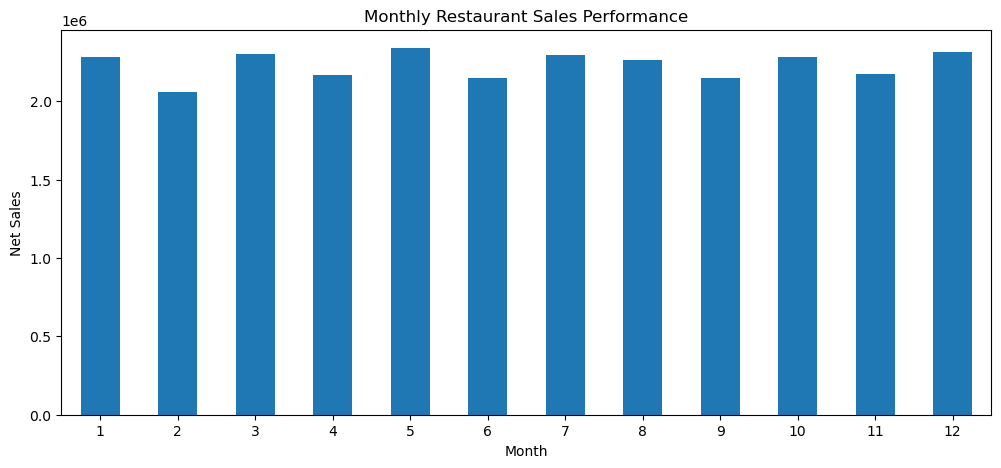

In [26]:
plt.figure(figsize=(12,5))

monthly_sales.plot(kind="bar")

plt.title("Monthly Restaurant Sales Performance")
plt.xlabel("Month")
plt.ylabel("Net Sales")
plt.xticks(rotation=0)

plt.show()


In [27]:
channel_sales = orders[
    orders["order_status"] == "Completed"
].groupby("sales_channel_clean")["net_sales"].sum().sort_values(ascending=False)

channel_sales

sales_channel_clean
dine-in     9203561.10
swiggy      8350404.15
zomato      7031946.90
takeaway    2184524.10
Name: net_sales, dtype: float64

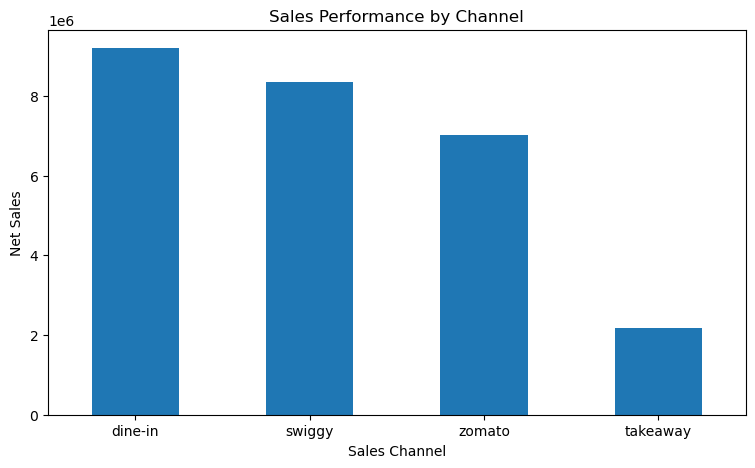

In [29]:
channel_sales.plot(kind="bar",figsize=(9,5))
plt.title("Sales Performance by Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Net Sales")
plt.xticks(rotation=0)
plt.show()

In [30]:
channel_performance = orders[
    orders["order_status"] == "Completed"
].groupby("sales_channel_clean").agg(
    total_orders=("order_id", "count"),
    total_revenue=("net_sales", "sum"),
    avg_order_value=("net_sales", "mean")
).round(2)

channel_performance

,total_orders,total_revenue,avg_order_value
sales_channel_clean,,,
dine-in,12675,9203561.10,726.12
swiggy,11445,8350404.15,729.61
takeaway,2978,2184524.10,733.55
zomato,9700,7031946.90,724.94


In [31]:
store_performance = orders[
    orders["order_status"] == "Completed"
].groupby("store_id").agg(
    total_orders=("order_id", "count"),
    total_revenue=("net_sales", "sum"),
    avg_order_value=("net_sales", "mean")
).reset_index()

store_performance = store_performance.merge(
    stores[["store_id", "store_name", "region", "city"]],
    on="store_id",
    how="left"
)

store_performance = store_performance.sort_values(
    by="total_revenue", ascending=False
)

store_performance.head(10)

,store_id,total_orders,total_revenue,avg_order_value,store_name,region,city
19,S020,1289,945621.00,733.608223,Bhubaneswar Mall,East,Bhubaneswar
2,S003,1269,942307.25,742.558905,Noida High Street,North,Noida
12,S013,1254,927881.10,739.937081,Bengaluru Central,South,Bengaluru
16,S017,1253,923966.25,737.403232,Coimbatore Market,South,Coimbatore
13,S014,1254,917653.00,731.780702,Chennai Mall,South,Chennai
20,S021,1253,911309.65,727.302195,Patna High Street,East,Patna
29,S030,1241,907641.10,731.378807,Udaipur Express,Central,Udaipur
14,S015,1246,907640.35,728.443299,Hyderabad High Street,South,Hyderabad
6,S007,1244,906766.30,728.911817,Mumbai Central,West,Mumbai
28,S029,1261,906714.50,719.044013,Agra Market,Central,Agra


In [33]:
store_performance.tail(10)

,store_id,total_orders,total_revenue,avg_order_value,store_name,region,city
27,S028,1203,877218.80,729.192685,Kanpur Sector,Central,Kanpur
5,S006,1199,877155.70,731.572727,Lucknow Express,North,Lucknow
24,S025,1210,875620.95,723.653678,Bhopal Central,Central,Bhopal
11,S012,1185,871852.00,735.740084,Nagpur Express,West,Nagpur
26,S027,1231,871552.00,708.003249,Jabalpur High Street,Central,Jabalpur
4,S005,1213,868893.70,716.317972,Chandigarh Market,North,Chandigarh
9,S010,1228,866170.25,705.350366,Surat Sector,West,Surat
17,S018,1195,858115.15,718.087992,Mysuru Express,South,Mysuru
25,S026,1182,856079.10,724.263198,Raipur Mall,Central,Raipur
0,S001,1154,845962.30,733.069584,Delhi Central,North,Delhi


In [34]:
region_performance = orders[
    orders["order_status"] == "Completed"
].merge(
    stores[["store_id", "region"]],
    on="store_id",
    how="left"
)

region_performance = region_performance.groupby("region").agg(
    total_orders=("order_id", "count"),
    total_revenue=("net_sales", "sum"),
    avg_order_value=("net_sales", "mean")
).reset_index()

region_performance = region_performance.sort_values(
    by="total_revenue", ascending=False
)

region_performance

,region,total_orders,total_revenue,avg_order_value
1,East,7454,5442000.05,730.077817
3,South,7429,5416479.75,729.099441
4,West,7352,5321708.50,723.845008
2,North,7235,5295421.50,731.917277
0,Central,7328,5294826.45,722.547278


In [36]:
product_performance = orders[
    orders["order_status"] == "Completed"
].merge(
    order_items,
    on="order_id",
    how="inner",
    suffixes=("_order", "_item")
).merge(
    products[["product_id", "product_name", "category", "unit_food_cost"]],
    on="product_id",
    how="left"
)

product_performance = product_performance.groupby(
    ["product_id", "product_name", "category"]
).agg(
    total_quantity=("quantity", "sum"),
    total_orders=("order_id", "nunique"),
    total_revenue=("net_sales_item", "sum")
).reset_index()

product_performance = product_performance.sort_values(
    by="total_quantity", ascending=False
)

product_performance.head(10)

,product_id,product_name,category,total_quantity,total_orders,total_revenue
16,P017,Peri Peri Chicken Pizza,Pizza,2825,1925,454914.20
33,P034,Iced Tea,Beverages,2786,1898,503344.80
28,P029,Coleslaw,Sides,2745,1850,731621.70
6,P007,Mushroom Swiss Burger,Burgers,2725,1827,516146.30
8,P009,BBQ Chicken Burger,Burgers,2710,1825,566509.20
26,P027,Potato Wedges,Sides,2694,1854,433670.90
40,P041,Chocolate Brownie,desserts,2691,1826,379592.40
45,P046,Choco Chip Cookie,Desserts,2683,1838,328872.60
24,P025,Onion Rings,Sides,2675,1828,482942.25
20,P021,French Fries,Sides,2671,1840,835331.00


In [37]:
product_performance.tail(10)

,product_id,product_name,category,total_quantity,total_orders,total_revenue
48,P049,Caramel Pudding,Desserts,2556,1765,483928.20
35,P036,Chocolate Shake,Beverages,2547,1775,458806.95
43,P044,Gulab Jamun,Desserts,2543,1739,287563.50
11,P012,Farmhouse Pizza,Pizza,2542,1763,675570.60
9,P010,Mexican Bean Burger,Burgers,2541,1739,528698.85
17,P018,Veggie Delight Pizza,Pizza,2539,1784,481599.90
44,P045,Blueberry Cheesecake,desserts,2534,1758,674928.90
47,P048,Rasmalai,Desserts,2533,1746,311644.65
23,P024,Cheese Garlic Bread,Sides,2530,1753,528140.40
2,P003,Crispy Chicken Burger,Burgers,2521,1714,357324.35
